In [3]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt




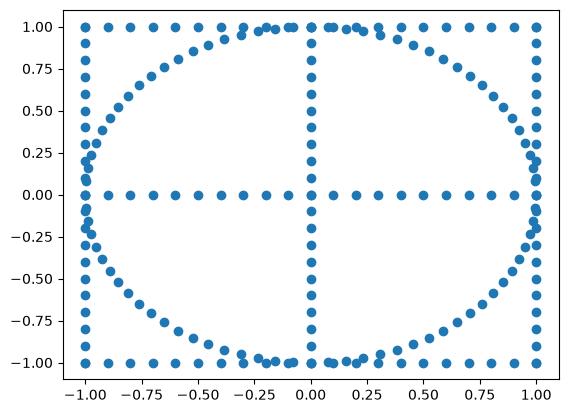

In [58]:
lv=np.linspace(-1,1,21); zv=np.zeros(21); ov=np.ones(21)
x=np.hstack([np.sin(np.linspace(0,2*np.pi,81)),zv,lv,lv,lv,ov,-ov])
y=np.hstack([np.cos(np.linspace(0,2*np.pi,81)),lv,zv,ov,-ov,lv,lv])
z=np.ones(207)

plt.scatter(x,y)

In [59]:
phi = np.deg2rad(0)
theta = np.deg2rad(90)
x0 = 0
y0 = 0
alph_x = 1.0
alph_y = 1.0

cos_phi = np.cos(phi)
sin_phi = np.sin(phi)


In [60]:
alpha = np.deg2rad(0)
beta = np.deg2rad(20)
gamma = np.deg2rad(10)
t_vec = np.array([1, 0, 0]).reshape((3,1))


In [61]:

def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0,  0],
                     [0, c, -s],
                     [0, s,  c]])

def Ry(b):
    c, s = np.cos(b), np.sin(b)
    return np.array([[ c, 0, s],
                     [ 0, 1, 0],
                     [-s, 0, c]])

def Rz(g):
    c, s = np.cos(g), np.sin(g)
    return np.array([[c, -s, 0],
                     [s,  c, 0],
                     [0,  0, 1]])

R_c = Rx(alpha) @ Ry(beta) @ Rz(gamma)
print(R_c)



[[ 0.92541658 -0.16317591  0.34202014]
 [ 0.17364818  0.98480775  0.        ]
 [-0.33682409  0.05939117  0.93969262]]


In [62]:
X_c = np.hstack((
    np.vstack((R_c, np.zeros(3))),
    np.vstack((- R_c @ t_vec, 1))
))
print(X_c)

[[ 0.92541658 -0.16317591  0.34202014 -0.92541658]
 [ 0.17364818  0.98480775  0.         -0.17364818]
 [-0.33682409  0.05939117  0.93969262  0.33682409]
 [ 0.          0.          0.          1.        ]]


In [63]:
T = np.array([
    [1, 0, x0],
    [0, 1, y0],
    [0, 0, 1]
])
R = np.array([
    [cos_phi, sin_phi, 0],
    [-sin_phi, cos_phi, 0],
    [0, 0, 1]
])
D = np.identity(3)
D[0,0] = alph_x
D[1,1] = alph_y
S = np.array([
    [1, - 1 / np.tan(theta), 0],
    [0, 1 / np.sin(theta), 0],
    [0, 0, 1]
])

K = T @ R @ D @ S
print(K)

[[ 1.000000e+00 -6.123234e-17  0.000000e+00]
 [ 0.000000e+00  1.000000e+00  0.000000e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00]]


In [64]:
K_with_0 = np.hstack(
    (K, 
     np.zeros((3, 1))
    )
)
print(K_with_0)

[[ 1.000000e+00 -6.123234e-17  0.000000e+00  0.000000e+00]
 [ 0.000000e+00  1.000000e+00  0.000000e+00  0.000000e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00  0.000000e+00]]


In [65]:
X_whatever = K_with_0 @ X_c

In [66]:
values_projected_x_list = []
values_projected_y_list = []
for x_value, y_value, z_value in zip(x, y, z):
    X_i = X_whatever @ np.array([x_value, y_value, z_value, 1]).reshape((4,1))
    
    value_projected_x = X_i[0] / X_i[2]
    value_projected_y = X_i[1] / X_i[2]
    values_projected_x_list.append(value_projected_x)
    values_projected_y_list.append(value_projected_y)
    


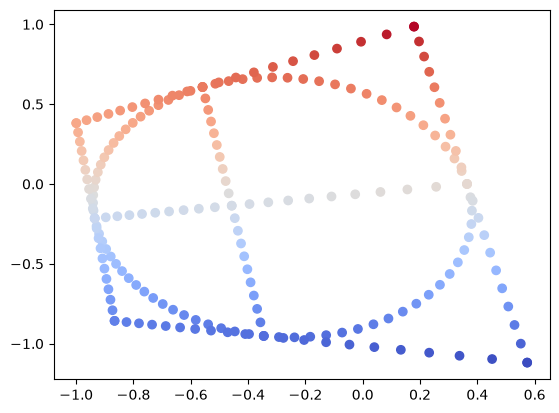

In [68]:
color_r = np.linspace(0, 1.0, 207)
plt.scatter(np.array(values_projected_x_list), np.array(values_projected_y_list), c=np.array(values_projected_y_list), cmap="coolwarm")